# Venta de propiedades nuevas en Moscú

EDA de `new_builds.csv`: distribución de las variables y asociaciones con `price_rub`, como base para la selección de predictores OLS.
Se conservan los anuncios originales; no se imputan datos ni se eliminan observaciones o valores extremos.


In [1]:
from pathlib import Path

# Buscar la raiz desde el directorio de ejecucion o cualquiera de sus padres.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "Data").is_dir() and (candidate / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontro la raiz del proyecto con Data/ y requirements.txt.")
DATA_DIR = PROJECT_ROOT / "Data"

def encontrar_archivo_data(nombre_archivo):
    ruta = DATA_DIR / nombre_archivo
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontro {nombre_archivo} en Data/.")
    return ruta

import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 45)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

CONFIG = {'dataset_file': 'new_builds.csv', 'temporal_cols': ['date_posted', 'completion_year'], 'identifier_cols': ['id', 'complex_id'], 'descriptions': {'id': 'Identificador del registro o anuncio.', 'date_posted': 'Fecha de publicacion del anuncio.', 'district': 'Distrito o zona donde se ubica la propiedad.', 'okrug': 'Okrug o circunscripcion administrativa de Moscu.', 'lat': 'Latitud geografica aproximada de la propiedad.', 'lon': 'Longitud geografica aproximada de la propiedad.', 'total_area': 'Superficie total de la propiedad, en metros cuadrados.', 'rooms': 'Cantidad de habitaciones principales.', 'floor': 'Piso donde se ubica la unidad.', 'total_floors': 'Cantidad total de pisos del edificio.', 'metro_station': 'Estacion de metro mas cercana.', 'metro_line': 'Linea de metro asociada a la estacion mas cercana.', 'metro_distance_min': 'Tiempo estimado hasta el metro, en minutos.', 'to_center_km': 'Distancia aproximada al centro de Moscu, en kilometros.', 'price_rub': 'Precio total de venta, en rublos.', 'price_per_sqm': 'Precio por metro cuadrado, en rublos por metro cuadrado.', 'mortgage_rate_at_listing': 'Tasa hipotecaria disponible al momento de publicacion, en porcentaje.', 'complex_id': 'Identificador del complejo residencial.', 'complex_name': 'Nombre del complejo residencial.', 'developer': 'Empresa desarrolladora del proyecto.', 'complex_class': 'Clase o segmento comercial del complejo.', 'completion_year': 'Anio de entrega o finalizacion prevista del complejo.', 'ready_status': 'Estado de disponibilidad o avance de la construccion.', 'deal_type': 'Tipo de operacion o contrato de venta.', 'subsidized_mortgage': 'Indica si la oferta incluye hipoteca subsidiada.'}, 'labels': {'id': 'ID', 'date_posted': 'Fecha de publicacion', 'district': 'Distrito', 'okrug': 'Okrug', 'lat': 'Latitud', 'lon': 'Longitud', 'total_area': 'Superficie total', 'living_area': 'Superficie habitable', 'kitchen_area': 'Superficie de cocina', 'rooms': 'Habitaciones', 'floor': 'Piso', 'total_floors': 'Pisos totales', 'building_year': 'Anio de construccion', 'building_type': 'Tipo de edificio', 'ceiling_height': 'Altura de techo', 'has_balcony': 'Tiene balcon', 'renovation': 'Renovacion', 'metro_station': 'Estacion de metro', 'metro_line': 'Linea de metro', 'metro_distance_min': 'Distancia al metro', 'metro_distance_type': 'Tipo de distancia al metro', 'to_center_km': 'Distancia al centro', 'price_rub': 'Precio de venta', 'price_per_sqm': 'Precio por m2', 'mortgage_rate_at_listing': 'Tasa hipotecaria', 'seller_type': 'Tipo de vendedor', 'complex_id': 'ID del complejo', 'complex_name': 'Nombre del complejo', 'developer': 'Desarrollador', 'complex_class': 'Clase del complejo', 'completion_year': 'Anio de entrega', 'ready_status': 'Estado de entrega', 'deal_type': 'Tipo de operacion', 'subsidized_mortgage': 'Hipoteca subsidiada'}, 'units': {'total_area': 'm²', 'living_area': 'm²', 'kitchen_area': 'm²', 'ceiling_height': 'm', 'metro_distance_min': 'minutos', 'to_center_km': 'km', 'price_rub': 'RUB', 'price_per_sqm': 'RUB/m²', 'mortgage_rate_at_listing': '%'}, 'histogram_cols': ['price_rub', 'price_per_sqm', 'total_area', 'rooms', 'floor', 'metro_distance_min', 'to_center_km', 'total_floors', 'completion_year', 'mortgage_rate_at_listing'], 'bar_cols': [{'col': 'okrug', 'top_n': None}, {'col': 'district', 'top_n': 10}, {'col': 'complex_class', 'top_n': None}, {'col': 'ready_status', 'top_n': None}, {'col': 'deal_type', 'top_n': None}], 'box_numeric_cols': ['price_rub', 'price_per_sqm', 'total_area', 'metro_distance_min'], 'price_category_cols': [{'col': 'rooms', 'top_n': None, 'sort_numeric': True}, {'col': 'okrug', 'top_n': None, 'sort_numeric': False}, {'col': 'complex_class', 'top_n': None, 'sort_numeric': False}]}
DATASET_FILE = CONFIG["dataset_file"]

DATA_PATH = encontrar_archivo_data(DATASET_FILE)

df = pd.read_csv(DATA_PATH)
from scipy.stats import linregress


Los precios distritales se incorporan por mes de publicación, distrito y okrug; los datos de metro, por estación y línea, con prefijo `metro_` para preservar la ubicación original.
Ambas uniones son izquierdas y de muchos a uno. El código auxiliar queda plegado; conserva validaciones de claves, tipos, correspondencias y valores originales.


In [2]:
# Referencias mensuales: mes contemporáneo del anuncio, sin datos de alquiler.
district_join_keys = ['year_month', 'district', 'okrug']
district_sales_columns = ['secondary_price_per_sqm', 'newbuild_price_per_sqm',
    'secondary_mom_change_pct', 'newbuild_mom_change_pct', 'n_listings_secondary',
    'n_listings_newbuild', 'cbr_key_rate_pct', 'avg_mortgage_rate_pct']
district_prices = pd.read_csv(encontrar_archivo_data('district_prices_monthly.csv'))
district_prices_sales = district_prices[district_join_keys + district_sales_columns].copy()
assert not district_prices_sales.duplicated(district_join_keys).any()
df_venta_district_prices = df.assign(date_posted_dt=pd.to_datetime(df['date_posted'], errors='raise'))
df_venta_district_prices['year_month'] = df_venta_district_prices['date_posted_dt'].dt.strftime('%Y-%m')
df_venta_district_prices = df_venta_district_prices.merge(district_prices_sales,
    on=district_join_keys, how='left', validate='many_to_one', indicator='_merge_district_prices')

# Prefijo metro_: preservar los atributos originales de la propiedad.
metro_join_keys = ['metro_station', 'metro_line']
metro_added_columns = ['metro_lat', 'metro_lon', 'metro_year_opened', 'metro_to_center_km']
metro_stations = pd.read_csv(encontrar_archivo_data('metro_stations.csv'))
metro_stations_sales = metro_stations[['station_name', 'line', 'lat', 'lon', 'year_opened', 'to_center_km']].rename(
    columns=dict(zip(['station_name', 'line', 'lat', 'lon', 'year_opened', 'to_center_km'],
                     metro_join_keys + metro_added_columns)))
assert not metro_stations_sales.duplicated(metro_join_keys).any()
df_venta_enriquecido = df_venta_district_prices.merge(metro_stations_sales,
    on=metro_join_keys, how='left', validate='many_to_one', indicator='_merge_metro_stations')

def origen_nulos(auxiliar, columnas, indicador):
    match = df_venta_enriquecido[indicador].eq('both')
    return pd.DataFrame({
        'nulos_en_auxiliar': auxiliar[columnas].isna().sum(),
        'nulos_en_final_con_match': df_venta_enriquecido.loc[match, columnas].isna().sum(),
        'nulos_en_final_sin_match': df_venta_enriquecido.loc[~match, columnas].isna().sum(),
    })
district_null_origin = origen_nulos(district_prices_sales, district_sales_columns, '_merge_district_prices')
metro_null_origin = origen_nulos(metro_stations_sales, metro_added_columns, '_merge_metro_stations')


def tipo_esperado_ok(serie, tipo_esperado):
    if tipo_esperado == "datetime":
        return pd.api.types.is_datetime64_any_dtype(serie)
    if tipo_esperado == "numeric":
        return pd.api.types.is_numeric_dtype(serie)
    if tipo_esperado == "text":
        return pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie)
    return False

expected_new_column_types = {
    "date_posted_dt": "datetime",
    "year_month": "text",
    "secondary_price_per_sqm": "numeric",
    "newbuild_price_per_sqm": "numeric",
    "secondary_mom_change_pct": "numeric",
    "newbuild_mom_change_pct": "numeric",
    "n_listings_secondary": "numeric",
    "n_listings_newbuild": "numeric",
    "cbr_key_rate_pct": "numeric",
    "avg_mortgage_rate_pct": "numeric",
    "metro_lat": "numeric",
    "metro_lon": "numeric",
    "metro_year_opened": "numeric",
    "metro_to_center_km": "numeric",
}

type_validation = pd.DataFrame(
    [
        {
            "columna": col,
            "tipo_esperado": expected_type,
            "tipo_observado": str(df_venta_enriquecido[col].dtype),
            "cumple": tipo_esperado_ok(df_venta_enriquecido[col], expected_type),
        }
        for col, expected_type in expected_new_column_types.items()
        if col in df_venta_enriquecido.columns
    ]
)

# Recuperar el resultado existente, sin rehacer ni modificar las uniones.
from pathlib import Path
import pandas as pd
from IPython.display import display

df_exportacion = df_venta_enriquecido
claves_distrito_exportacion = ["year_month", "district", "okrug"]
claves_metro_exportacion = ["metro_station", "metro_line"]
columnas_originales_exportacion = df.columns.tolist()
columnas_esperadas_exportacion = (
    columnas_originales_exportacion + ["date_posted_dt", "year_month"]
    + district_sales_columns + ["_merge_district_prices"]
    + metro_added_columns + ["_merge_metro_stations"]
)

control_exportacion = pd.Series({
    "observaciones_originales": len(df),
    "observaciones_integradas": len(df_exportacion),
    "columnas_originales": df.shape[1],
    "columnas_integradas": df_exportacion.shape[1],
    "id_unicos": df_exportacion["id"].nunique(),
    "id_nulos": df_exportacion["id"].isna().sum(),
    "id_duplicados": df_exportacion["id"].duplicated().sum(),
    "filas_duplicadas": df_exportacion.duplicated().sum(),
    "complejos_unicos": df_exportacion["complex_id"].nunique(),
    "celdas_nulas": df_exportacion.isna().sum().sum(),
}, name="valor")

auditoria_claves_exportacion = pd.DataFrame([
    {"dataset": nombre, "claves": ", ".join(claves),
     "filas_con_clave_nula": int(tabla[claves].isna().any(axis=1).sum()),
     "claves_repetidas": int(tabla.duplicated(claves).sum())}
    for nombre, tabla, claves in [
        ("Auxiliar precios", district_prices_sales, claves_distrito_exportacion),
        ("Auxiliar metro", metro_stations_sales, claves_metro_exportacion),
        ("Integrado: distrito/mes", df_exportacion, claves_distrito_exportacion),
        ("Integrado: estación/línea", df_exportacion, claves_metro_exportacion),
    ]
])

correspondencias_exportacion = pd.DataFrame([
    {"join": nombre, "con_match": int(df_exportacion[indicador].eq("both").sum()),
     "sin_match": int(df_exportacion[indicador].ne("both").sum()),
     "coincidencia_pct": df_exportacion[indicador].eq("both").mean() * 100}
    for nombre, indicador in [("Precios distritales", "_merge_district_prices"), ("Estaciones de metro", "_merge_metro_stations")]
])

faltantes_exportacion = pd.DataFrame({"nulos": df_exportacion.isna().sum(),
                                      "porcentaje_nulos": df_exportacion.isna().mean() * 100})

assert len(df) == len(df_venta_district_prices) == len(df_exportacion) == 8000
assert df_exportacion.columns.is_unique
assert df_exportacion.columns.tolist() == columnas_esperadas_exportacion
assert df_exportacion.shape[1] == 41
assert df_exportacion["id"].notna().all() and df_exportacion["id"].is_unique
assert not df_exportacion.duplicated().any()
assert auditoria_claves_exportacion["filas_con_clave_nula"].eq(0).all()
assert auditoria_claves_exportacion.loc[:1, "claves_repetidas"].eq(0).all()
assert correspondencias_exportacion["sin_match"].eq(0).all()
pd.testing.assert_frame_equal(
    df_exportacion[columnas_originales_exportacion].reset_index(drop=True),
    df.reset_index(drop=True), check_exact=True,
)
fechas_originales_exportacion = pd.to_datetime(df_exportacion["date_posted"], format="%Y-%m-%d", errors="raise")
pd.testing.assert_series_equal(fechas_originales_exportacion, df_exportacion["date_posted_dt"], check_names=False)
assert df_exportacion["year_month"].eq(df_exportacion["date_posted_dt"].dt.strftime("%Y-%m")).all()

# Comprobar los valores añadidos contra los auxiliares por sus claves únicas.
# reindex solo alinea la referencia de auditoría; no vuelve a integrar el dataset.
for auxiliar, claves, columnas in [
    (district_prices_sales, claves_distrito_exportacion, district_sales_columns),
    (metro_stations_sales, claves_metro_exportacion, metro_added_columns),
]:
    referencia = auxiliar.set_index(claves).reindex(pd.MultiIndex.from_frame(df_exportacion[claves]))
    pd.testing.assert_frame_equal(
        df_exportacion[columnas].reset_index(drop=True),
        referencia[columnas].reset_index(drop=True), check_exact=True,
    )

assert type_validation['cumple'].all()
diccionario_columnas = pd.DataFrame({
    'variable': df_venta_enriquecido.columns,
    'tipo': df_venta_enriquecido.dtypes.astype(str).values,
    'descripcion': [CONFIG['descriptions'].get(c, '') for c in df_venta_enriquecido],
})
print(f"{len(df):,} anuncios · {df.shape[1]} variables originales + "
      f"{df_venta_enriquecido.shape[1] - df.shape[1]} incorporadas o técnicas · "
      f"{control_exportacion['filas_duplicadas']} filas duplicadas")
display(correspondencias_exportacion)
faltantes = faltantes_exportacion.loc[faltantes_exportacion.nulos.gt(0)]
if not faltantes.empty:
    display(faltantes)
else:
    print('Sin valores faltantes en el dataset integrado.')


,join,con_match,sin_match,coincidencia_pct
0,Precios distritales,8000,0,100.00
1,Estaciones de metro,8000,0,100.00


8,000 anuncios · 25 variables originales + 16 incorporadas o técnicas · 0 filas duplicadas
Sin valores faltantes en el dataset integrado.


<details>
<summary>Diccionario y trazabilidad de las variables auxiliares</summary>

Las 25 variables originales se documentan en `CONFIG["descriptions"]`; `diccionario_columnas` conserva nombres y tipos de las 41 columnas.

| Variables incorporadas | Significado / unidad |
| --- | --- |
| `date_posted_dt`, `year_month` | Fecha convertida y clave mensual YYYY-MM; no reemplazan `date_posted`. |
| `secondary_price_per_sqm`, `newbuild_price_per_sqm` | Referencias distritales mensuales de usadas y nuevas (RUB/m²). |
| `secondary_mom_change_pct`, `newbuild_mom_change_pct` | Variaciones respecto del mes anterior (%). |
| `n_listings_secondary`, `n_listings_newbuild` | Cantidad de anuncios por distrito y mes. |
| `cbr_key_rate_pct`, `avg_mortgage_rate_pct` | Tasa de referencia y tasa hipotecaria promedio del mes (%). |
| `metro_lat`, `metro_lon` | Coordenadas de la estación (grados). |
| `metro_year_opened`, `metro_to_center_km` | Año de inauguración y distancia de la estación al centro (km). |
| `_merge_district_prices`, `_merge_metro_stations` | Controles de correspondencia: `both` o `left_only`. |

`price_per_sqm` es el precio unitario del anuncio; las referencias distritales describen su contexto.
`district_null_origin` y `metro_null_origin` distinguen faltantes heredados y faltas de correspondencia; las variaciones mensuales pueden ser nulas al inicio de la serie.
`control_exportacion`, `auditoria_claves_exportacion` y `type_validation` mantienen el detalle de los controles. `complex_id` puede repetirse entre unidades del mismo complejo.

</details>


## 1. Análisis univariado

Se resumen las variables numéricas sin identificadores y las frecuencias categóricas. Los percentiles, la asimetría y los boxplots permiten reconocer dispersión y extremos sin recortar la muestra.


In [3]:
temporal_cols = [c for c in CONFIG['temporal_cols'] if c in df]
identifier_cols = [c for c in CONFIG['identifier_cols'] if c in df]
numeric_cols = df.select_dtypes(include='number').columns.tolist()
boolean_cols = df.select_dtypes(include='bool').columns.tolist()
categorical_cols = [c for c in df if c not in temporal_cols + identifier_cols
                   and (pd.api.types.is_string_dtype(df[c])
                        or isinstance(df[c].dtype, pd.CategoricalDtype))] + boolean_cols


percentiles = [0.05, 0.25, 0.50, 0.75, 0.95]

estadistica_numerica = (
    df[numeric_cols]
    .describe(percentiles=percentiles)
    .T.rename(
        columns={
            "count": "observaciones",
            "mean": "media",
            "std": "desviacion_estandar",
            "min": "minimo",
            "5%": "percentil_5",
            "25%": "percentil_25",
            "50%": "mediana_percentil_50",
            "75%": "percentil_75",
            "95%": "percentil_95",
            "max": "maximo",
        }
    )
)

estadistica_numerica = estadistica_numerica.drop(index=identifier_cols, errors='ignore')
estadistica_numerica['asimetria'] = df[estadistica_numerica.index].skew()
display(estadistica_numerica)


,observaciones,media,desviacion_estandar,minimo,percentil_5,percentil_25,mediana_percentil_50,percentil_75,percentil_95,maximo,asimetria
lat,"8,000.00",55.71,0.15,55.27,55.40,55.63,55.75,55.82,55.89,56.01,-0.96
lon,"8,000.00",37.53,0.21,36.71,37.09,37.45,37.56,37.65,37.81,37.87,-1.27
total_area,"8,000.00",55.26,17.28,22.00,27.50,42.80,54.30,66.40,86.20,112.20,0.31
rooms,"8,000.00",1.69,1.00,0.00,0.00,1.00,2.00,2.00,3.00,4.00,0.34
floor,"8,000.00",12.85,7.75,1.00,2.00,6.00,12.00,19.00,27.00,35.00,0.35
total_floors,"8,000.00",24.72,4.98,17.00,17.00,22.00,25.00,30.00,35.00,35.00,0.27
completion_year,"8,000.00","2,025.94",1.09,"2,024.00","2,024.00","2,025.00","2,026.00","2,027.00","2,028.00","2,028.00",0.03
metro_distance_min,"8,000.00",169.01,187.26,1.00,11.00,38.00,107.00,212.00,629.00,960.00,1.85
to_center_km,"8,000.00",17.41,14.50,0.36,3.46,8.99,13.69,18.99,55.05,70.22,1.91
price_rub,"8,000.00","14,181,281.12","8,546,752.42","1,371,000.00","4,162,550.00","8,054,750.00","12,410,000.00","17,992,000.00","30,826,400.00","79,083,000.00",1.45


In [4]:
categorical_for_stats = [col for col in categorical_cols if col not in identifier_cols]

resumen_categoricas = []
tablas_frecuencia = {}

for col in categorical_for_stats:
    serie = df[col].astype("object").where(df[col].notna(), "Sin dato")
    frecuencias = (
        serie.value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="frecuencia_absoluta")
    )
    frecuencias["frecuencia_relativa_pct"] = frecuencias["frecuencia_absoluta"] / len(df) * 100
    tablas_frecuencia[col] = frecuencias

    categoria_mas_frecuente = frecuencias.iloc[0]["categoria"] if not frecuencias.empty else np.nan
    frecuencia_mas_frecuente = frecuencias.iloc[0]["frecuencia_absoluta"] if not frecuencias.empty else 0
    porcentaje_mas_frecuente = frecuencias.iloc[0]["frecuencia_relativa_pct"] if not frecuencias.empty else 0

    resumen_categoricas.append(
        {
            "columna": col,
            "categorias_unicas": df[col].nunique(dropna=True),
            "categoria_mas_frecuente": categoria_mas_frecuente,
            "frecuencia_categoria_mas_frecuente": frecuencia_mas_frecuente,
            "porcentaje_categoria_mas_frecuente": porcentaje_mas_frecuente,
        }
    )

resumen_categoricas = pd.DataFrame(resumen_categoricas).sort_values(
    "categorias_unicas", ascending=False
)
display(resumen_categoricas.style.format({"porcentaje_categoria_mas_frecuente": "{:.2f}%"}))


# Frecuencias completas disponibles sin repetir tablas por variable.


,columna,categorias_unicas,categoria_mas_frecuente,frecuencia_categoria_mas_frecuente,porcentaje_categoria_mas_frecuente
3,district,109,Meshchansky,274,3.43%
6,metro_station,104,Rechnoy Vokzal,162,2.02%
0,complex_name,20,Preobrazhenie Residence,597,7.46%
7,metro_line,12,Kaluzhsko-Rizhskaya,1099,13.74%
1,developer,11,LSR,855,10.69%
4,okrug,11,VAO,1363,17.04%
8,deal_type,4,DDU,4391,54.89%
2,complex_class,4,comfort,3314,41.42%
5,ready_status,2,under_construction,6988,87.35%
9,subsidized_mortgage,2,True,5247,65.59%


In [5]:
labels = CONFIG["labels"]
units = CONFIG["units"]

def etiqueta(col):
    return labels.get(col, col.replace("_", " ").title())

def etiqueta_eje(col):
    unidad = units.get(col)
    return f"{etiqueta(col)} ({unidad})" if unidad else etiqueta(col)

def formatear_eje_numerico(ax, col, axis="x"):
    target_axis = ax.xaxis if axis == "x" else ax.yaxis
    if col == "price_rub":
        target_axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x / 1_000_000:,.0f}M"))
    elif col == "price_per_sqm":
        target_axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x / 1_000:,.0f}k"))

def columnas_presentes(columnas):
    return [col for col in columnas if col in df.columns]


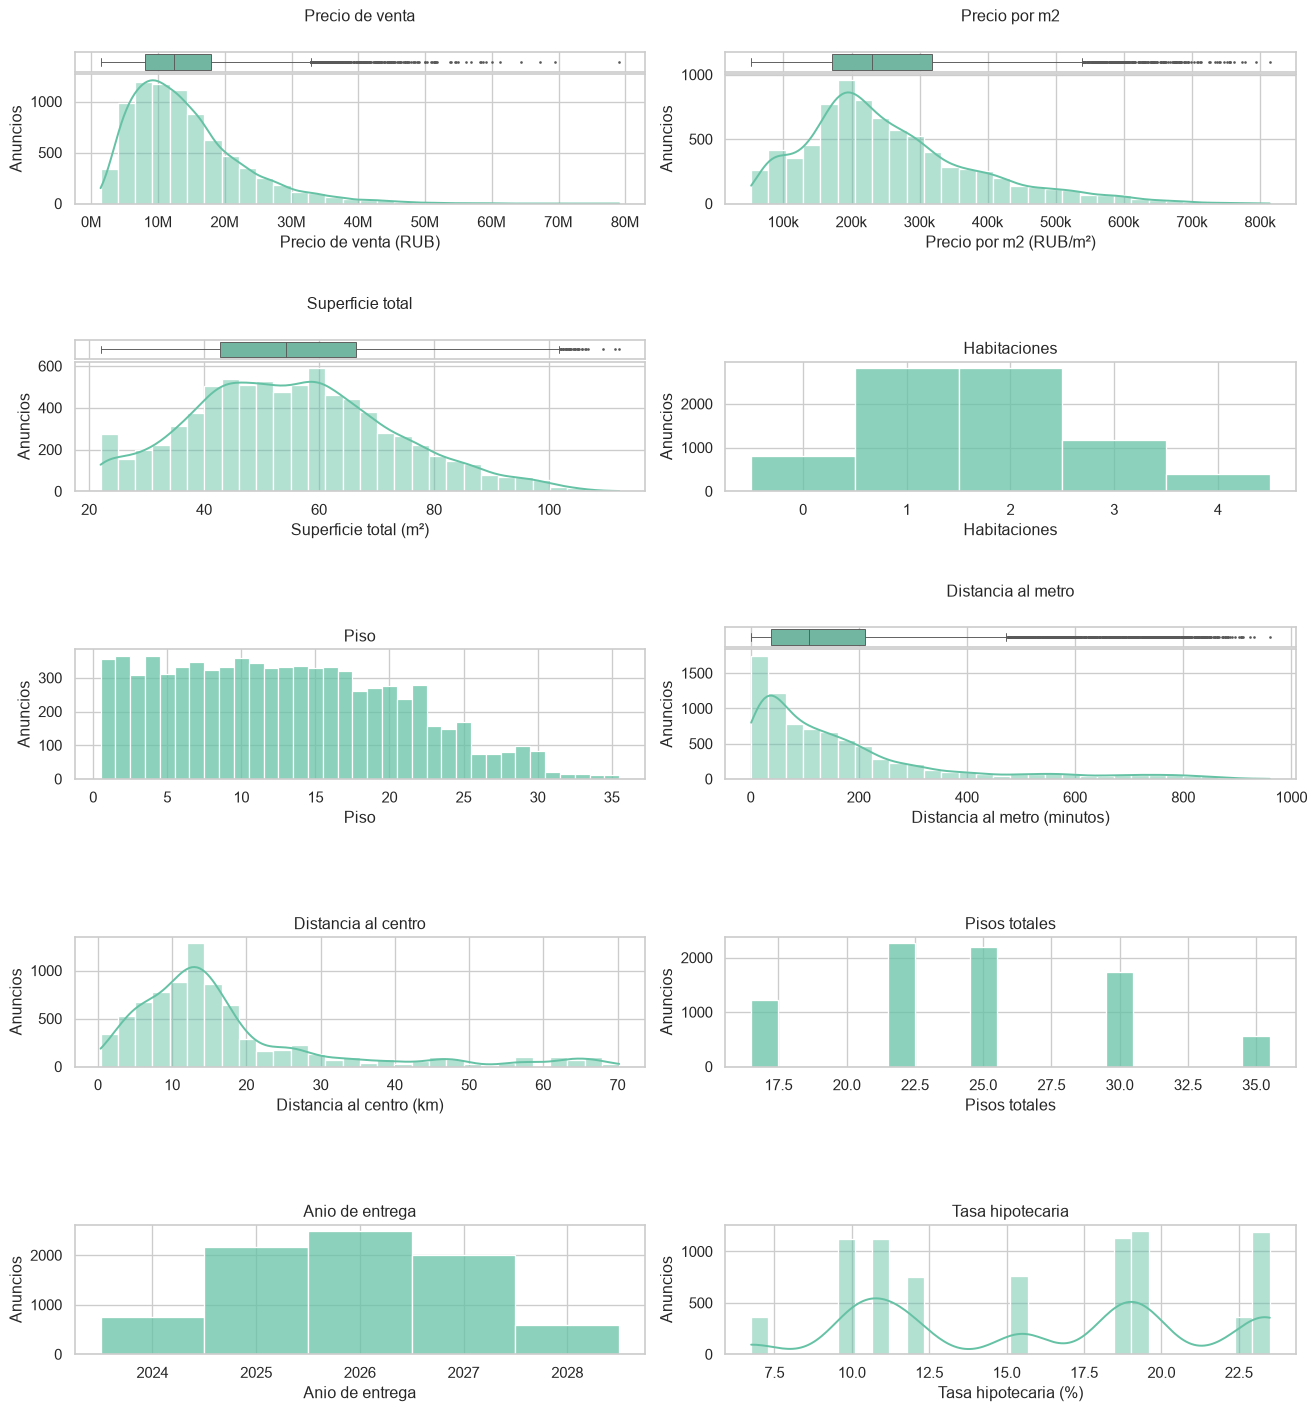

In [6]:
# Una fila por variable: histograma y, donde aporta, boxplot alineado.
columnas = columnas_presentes(CONFIG['histogram_cols'])
fig, axes = plt.subplots(math.ceil(len(columnas) / 2), 2,
                         figsize=(14, 3 * math.ceil(len(columnas) / 2)), squeeze=False)
for ax, col in zip(axes.flat, columnas):
    valores = df[col].dropna()
    discreta = col in ['rooms', 'floor', 'total_floors', 'completion_year']
    sns.histplot(valores, bins=30, discrete=discreta, kde=not discreta, ax=ax)
    ax.set(title=etiqueta(col), xlabel=etiqueta_eje(col), ylabel='Anuncios')
    formatear_eje_numerico(ax, col)
    if col in CONFIG['box_numeric_cols']:
        caja = ax.inset_axes([0, 1.02, 1, .15], sharex=ax)
        sns.boxplot(x=valores, ax=caja, fliersize=1, linewidth=.7)
        caja.tick_params(axis='x', labelbottom=False, bottom=False)
        caja.set(xlabel='', yticks=[])
        ax.set_title(etiqueta(col), pad=40)
for ax in list(axes.flat)[len(columnas):]:
    ax.set_visible(False)
fig.tight_layout(h_pad=3)
plt.show()


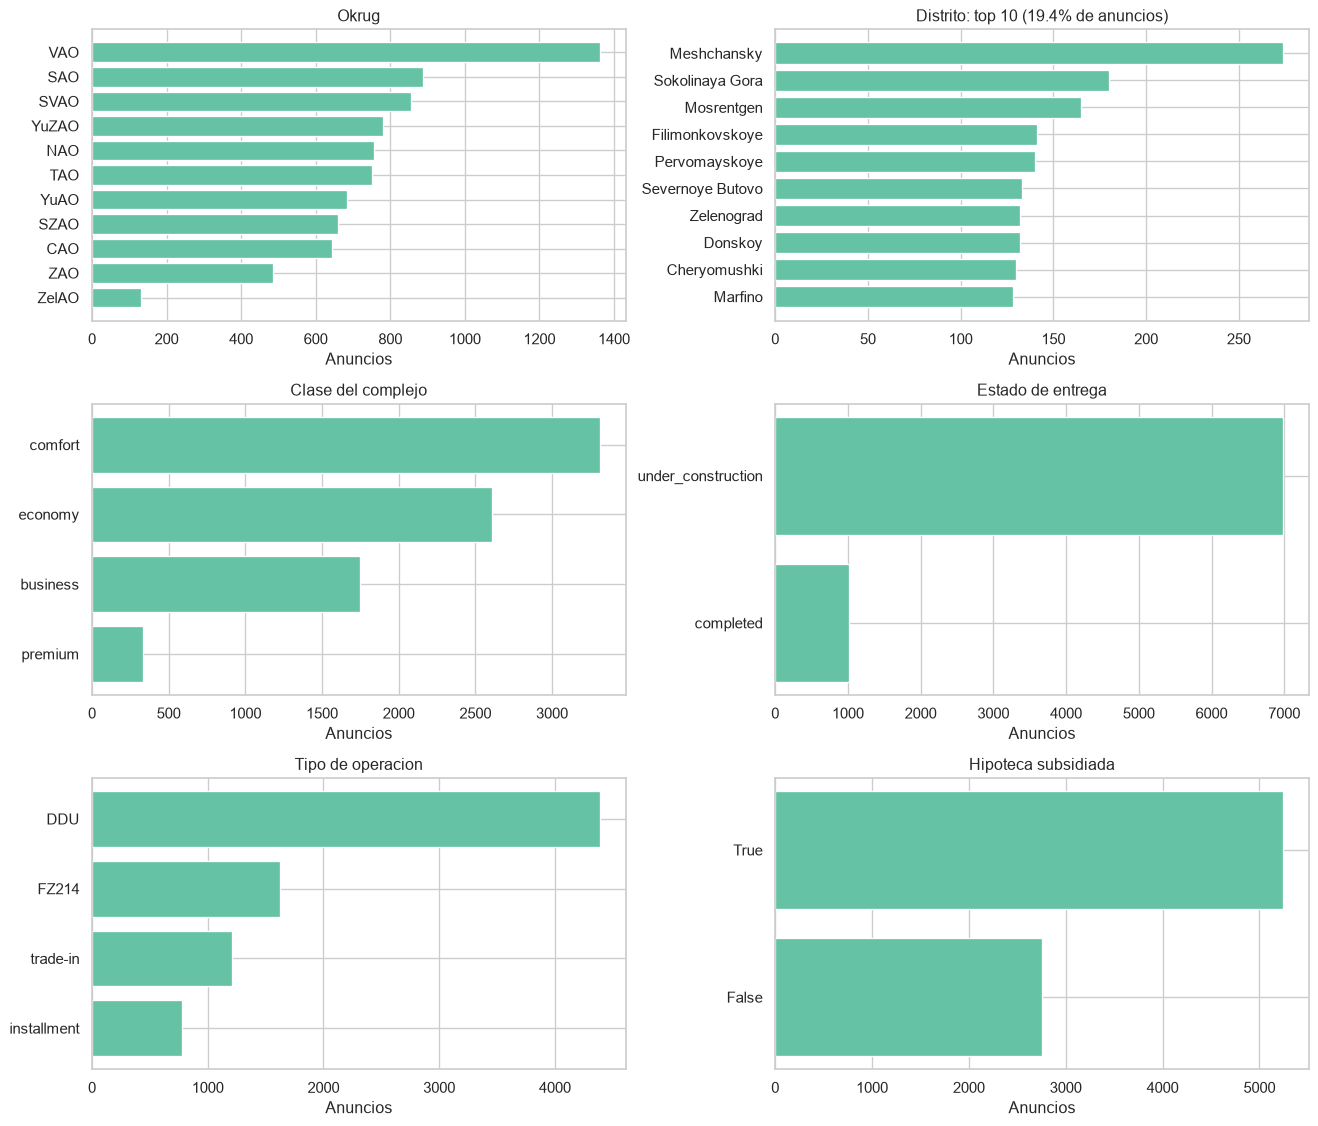

In [7]:
variables_barras = CONFIG['bar_cols'] + [{'col': 'subsidized_mortgage', 'top_n': None}]
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, item in zip(axes.flat, variables_barras):
    col, limite = item['col'], item['top_n']
    conteos = df[col].value_counts(dropna=False)
    visibles = conteos if limite is None else conteos.head(limite)
    ax.barh(visibles.index.astype(str), visibles.values)
    ax.invert_yaxis()
    cobertura = visibles.sum() / len(df) * 100
    titulo = etiqueta(col) if limite is None else f'{etiqueta(col)}: top {limite} ({cobertura:.1f}% de anuncios)'
    ax.set(title=titulo, xlabel='Anuncios')
fig.tight_layout()
plt.show()


El precio total y el precio por m² presentan asimetría positiva; sus extremos se conservan para evaluar transformaciones e influencia en OLS.
Las frecuencias de todas las categorías quedan en `tablas_frecuencia`; el gráfico de distritos explicita la cobertura del top 10.


## 2. Análisis bivariado

Objetivo: `price_rub`. Se excluyen IDs, controles técnicos, fechas duplicadas y `price_per_sqm` (derivada del objetivo).
Las referencias distritales se exploran, pero su disponibilidad al predecir y la posible fuga contemporánea deben verificarse antes del modelado.

**Variables numéricas.** Ajustes simples con intercepto: R² = r²; pendientes en RUB por unidad original.
Cada ajuste usa pares completos y finitos, informa su n y conserva los extremos. Las asociaciones son descriptivas, sin interpretación causal.


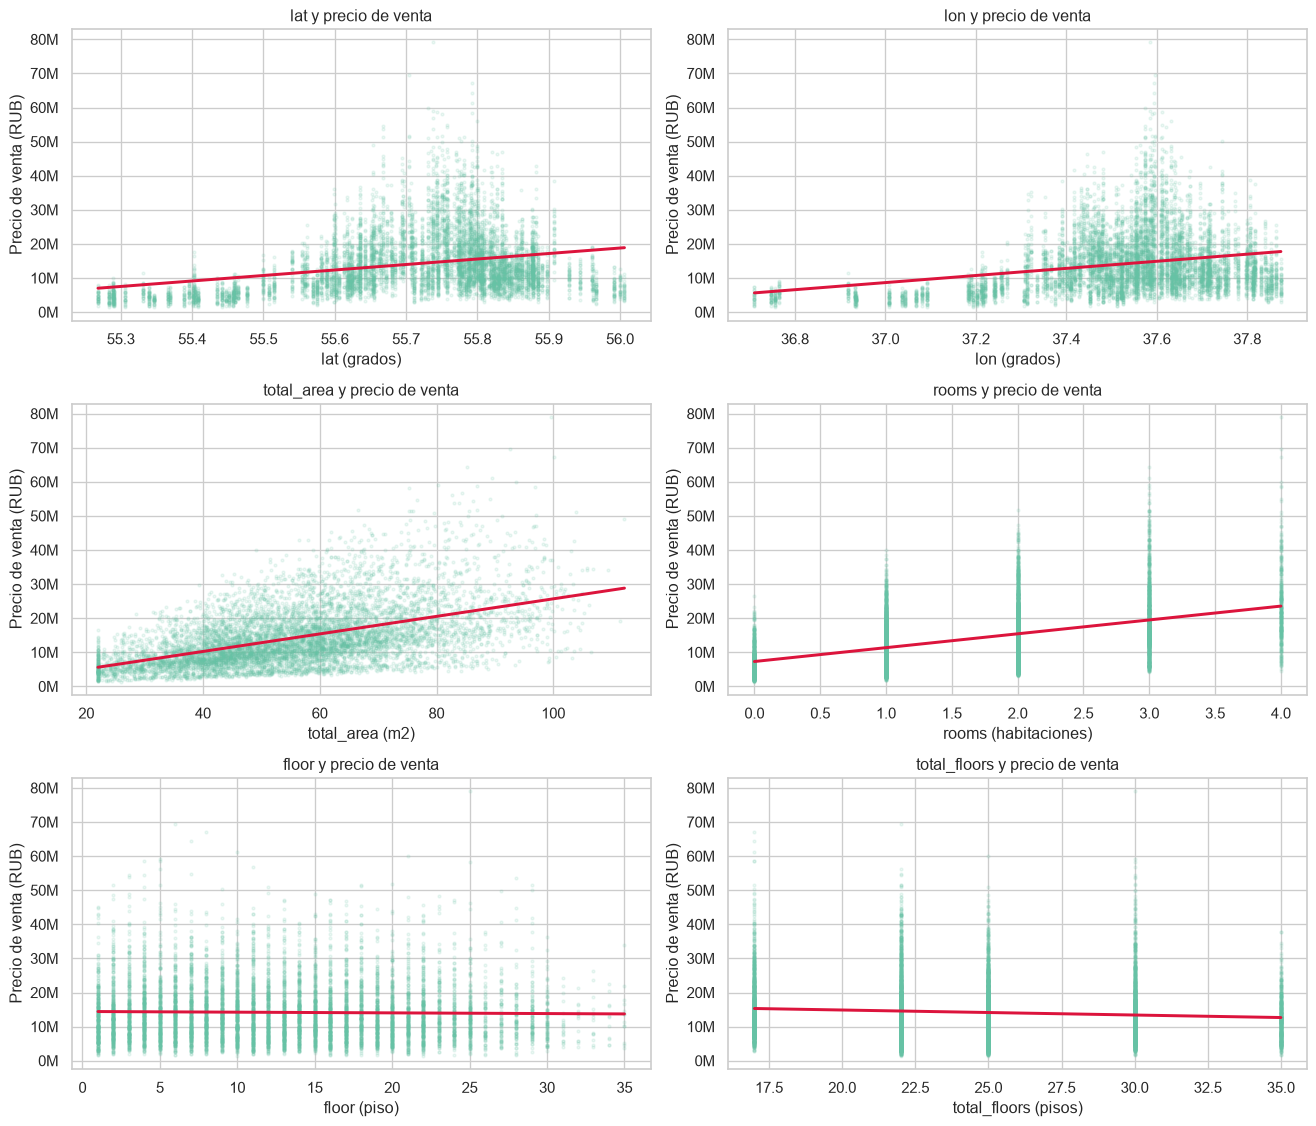

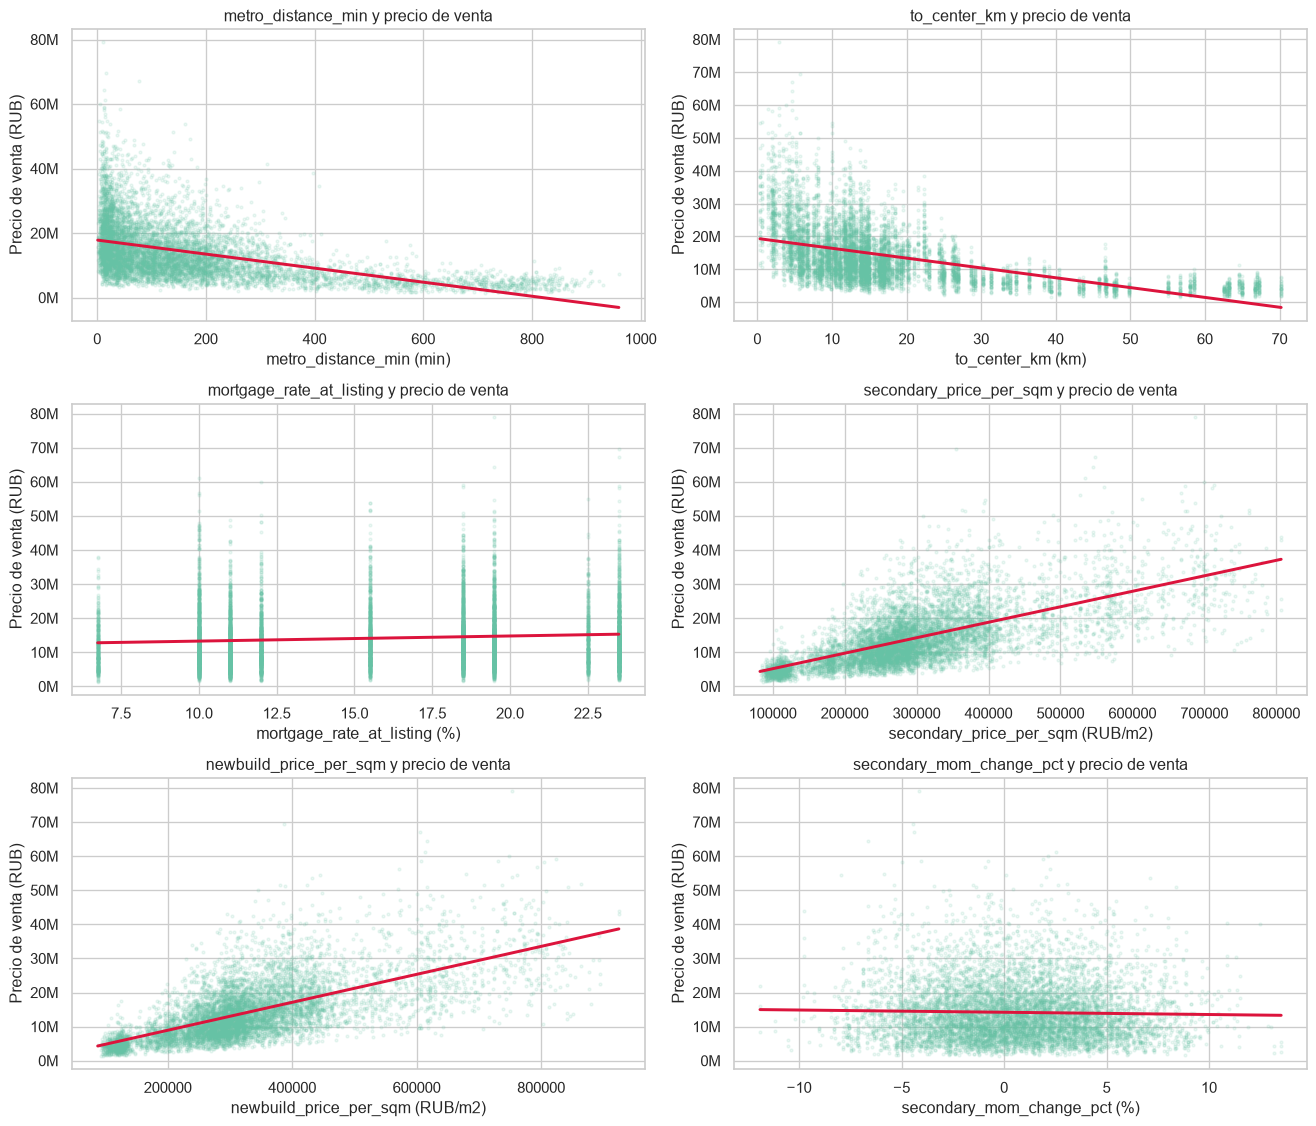

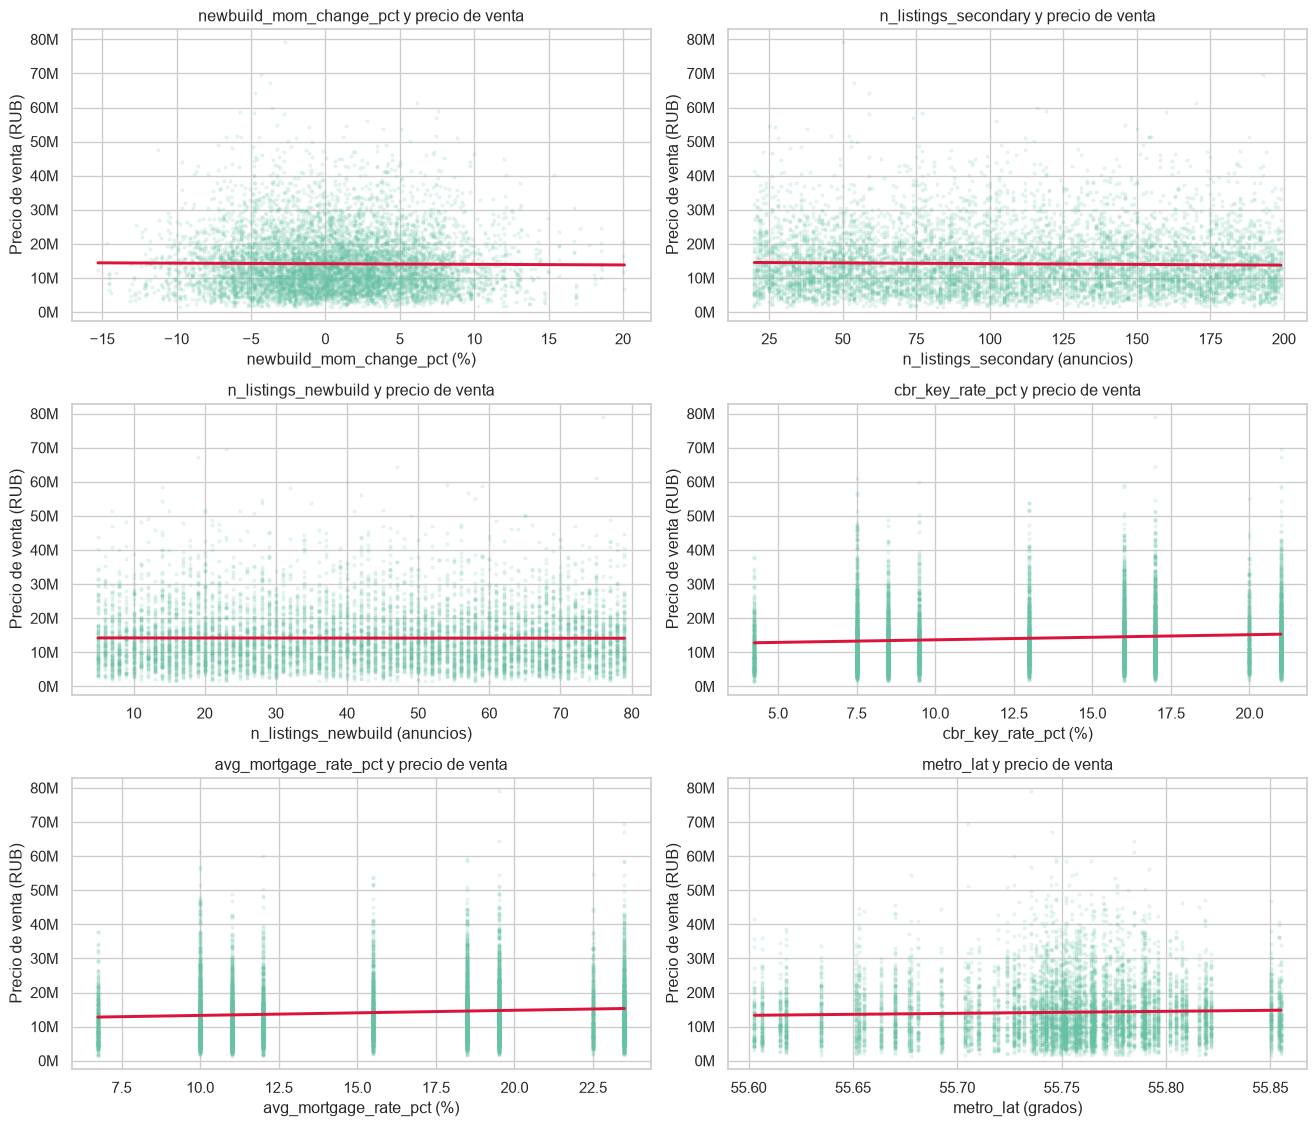

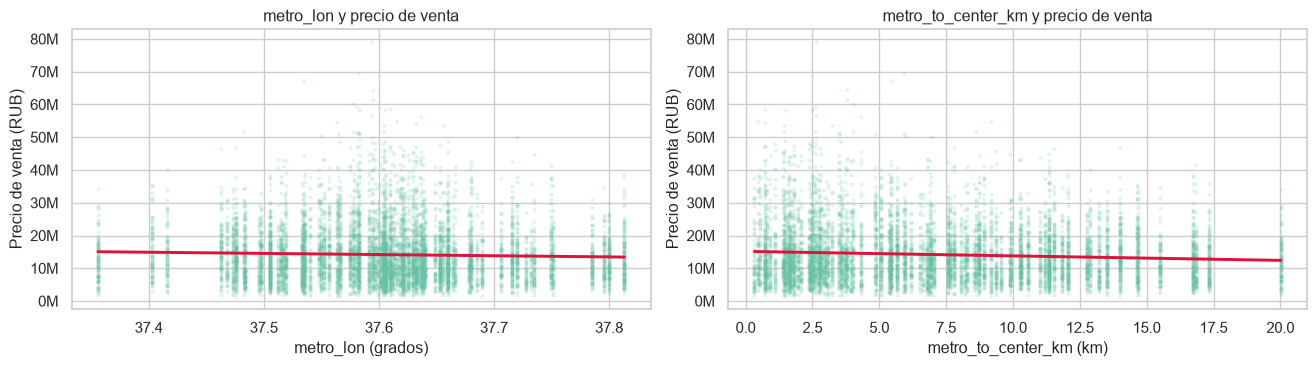

,variable,n,Pearson_r,R2,pendiente_RUB_por_unidad
9,secondary_price_per_sqm,8000,0.67,0.45,45.41
10,newbuild_price_per_sqm,8000,0.67,0.45,41.00
2,total_area,8000,0.52,0.27,"257,217.84"
7,to_center_km,8000,-0.51,0.26,"-299,402.67"
6,metro_distance_min,8000,-0.48,0.23,"-21,752.81"
3,rooms,8000,0.47,0.23,"4,062,765.69"
0,lat,8000,0.29,0.08,"16,107,537.87"
1,lon,8000,0.26,0.07,"10,416,772.59"
8,mortgage_rate_at_listing,8000,0.09,0.01,"150,124.31"
15,cbr_key_rate_pct,8000,0.09,0.01,"150,124.31"


In [8]:
objetivo = "price_rub"
datos_bivariados = df_venta_enriquecido.copy(deep=True)
exclusiones_bivariadas = {
    "id": "Identificador del anuncio",
    "complex_id": "Identificador del complejo; complex_name conserva su contexto",
    "price_per_sqm": "Derivada directamente del objetivo y de total_area",
    "_merge_district_prices": "Indicador tecnico de correspondencia",
    "_merge_metro_stations": "Indicador tecnico de correspondencia",
    "date_posted": "Representada mediante date_posted_dt",
    "year_month": "Representada mediante la evolucion mensual de date_posted_dt",
}
temporales = [c for c in ["date_posted_dt", "building_year", "completion_year", "metro_year_opened"] if c in datos_bivariados]
binarias = datos_bivariados.select_dtypes(include="bool").columns.tolist()
numericas = [c for c in datos_bivariados.select_dtypes(include="number") if c != objetivo and c not in temporales and c not in exclusiones_bivariadas]
categoricas = [c for c in datos_bivariados.columns if c not in numericas + temporales + binarias + [objetivo] and c not in exclusiones_bivariadas]

unidades_bivariadas = {"lat": "grados", "lon": "grados", "metro_lat": "grados", "metro_lon": "grados", "total_area": "m2", "living_area": "m2", "kitchen_area": "m2", "ceiling_height": "m", "metro_distance_min": "min", "to_center_km": "km", "metro_to_center_km": "km", "rooms": "habitaciones", "floor": "piso", "total_floors": "pisos", "mortgage_rate_at_listing": "%", "cbr_key_rate_pct": "%", "avg_mortgage_rate_pct": "%", "secondary_mom_change_pct": "%", "newbuild_mom_change_pct": "%", "secondary_price_per_sqm": "RUB/m2", "newbuild_price_per_sqm": "RUB/m2", "n_listings_secondary": "anuncios", "n_listings_newbuild": "anuncios"}

resultados_regresiones = []
for inicio in range(0, len(numericas), 6):
    lote = numericas[inicio:inicio + 6]
    fig, axes = plt.subplots(int(np.ceil(len(lote) / 2)), 2, figsize=(14, 4 * int(np.ceil(len(lote) / 2))), squeeze=False)
    for ax, variable in zip(axes.flat, lote):
        pares = datos_bivariados[[variable, objetivo]].dropna()
        pares = pares.loc[np.isfinite(pares).all(axis=1)]
        if len(pares) < 3 or pares[variable].nunique() < 2:
            resultados_regresiones.append({"variable": variable, "n": len(pares), "Pearson_r": np.nan, "R2": np.nan, "pendiente_RUB_por_unidad": np.nan})
            ax.text(.5, .5, "Datos insuficientes o variable constante", ha="center", transform=ax.transAxes)
        else:
            ajuste = linregress(pares[variable], pares[objetivo])
            resultados_regresiones.append({"variable": variable, "n": len(pares), "Pearson_r": ajuste.rvalue, "R2": ajuste.rvalue ** 2, "pendiente_RUB_por_unidad": ajuste.slope})
            sns.regplot(data=pares, x=variable, y=objetivo, ci=None, scatter_kws={"s": 5, "alpha": .12, "rasterized": True}, line_kws={"color": "crimson"}, ax=ax)
        ax.set(title=f"{variable} y precio de venta", xlabel=f"{variable} ({unidades_bivariadas.get(variable, 'unidad original')})", ylabel="Precio de venta (RUB)")
    for ax in list(axes.flat)[len(lote):]:
        ax.set_visible(False)
    for eje in axes.flat:
        formatear_eje_numerico(eje, objetivo, axis="y")
    fig.tight_layout()
    plt.show()
resultados_regresiones = pd.DataFrame(resultados_regresiones)
resultados_regresiones = resultados_regresiones.loc[resultados_regresiones.Pearson_r.abs().sort_values(ascending=False).index]

display(resultados_regresiones)


**Variables categóricas y binarias.** Se conservan todas las categorías, ordenadas por mediana; cada etiqueta informa su n.
Las distribuciones permiten comparar dispersión y solapamiento. Los grupos pequeños requieren cautela; sus diferencias no son efectos ajustados por superficie o ubicación.


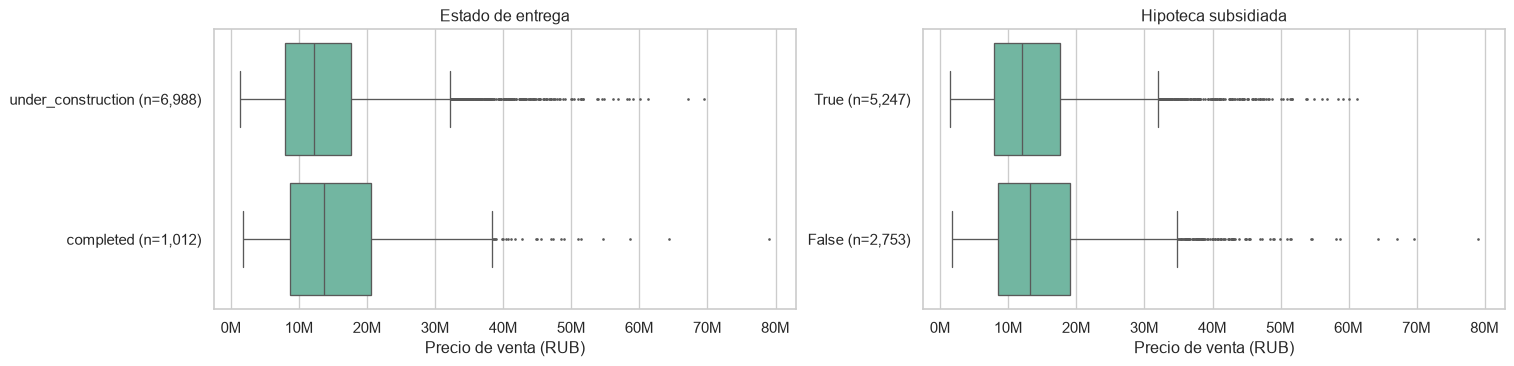

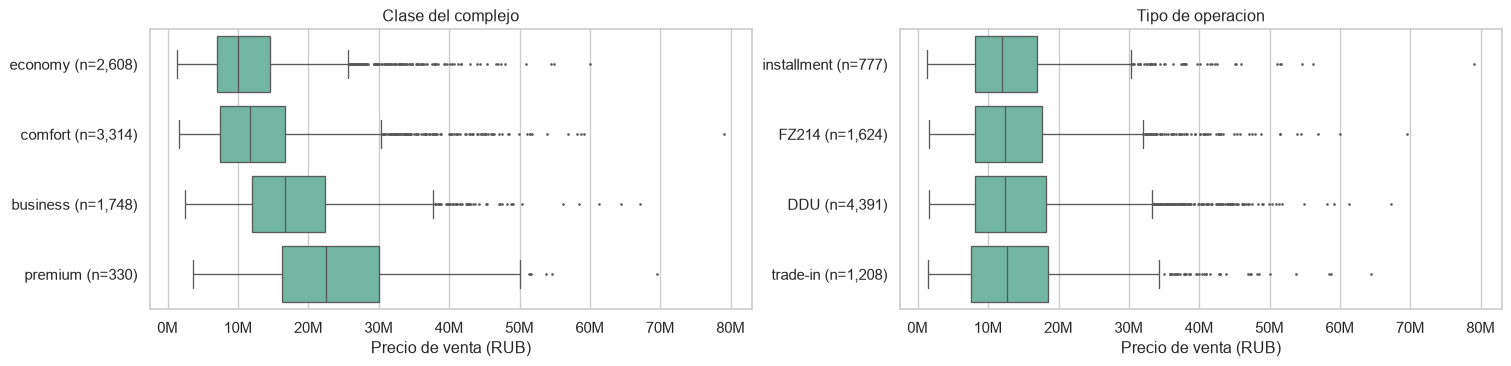

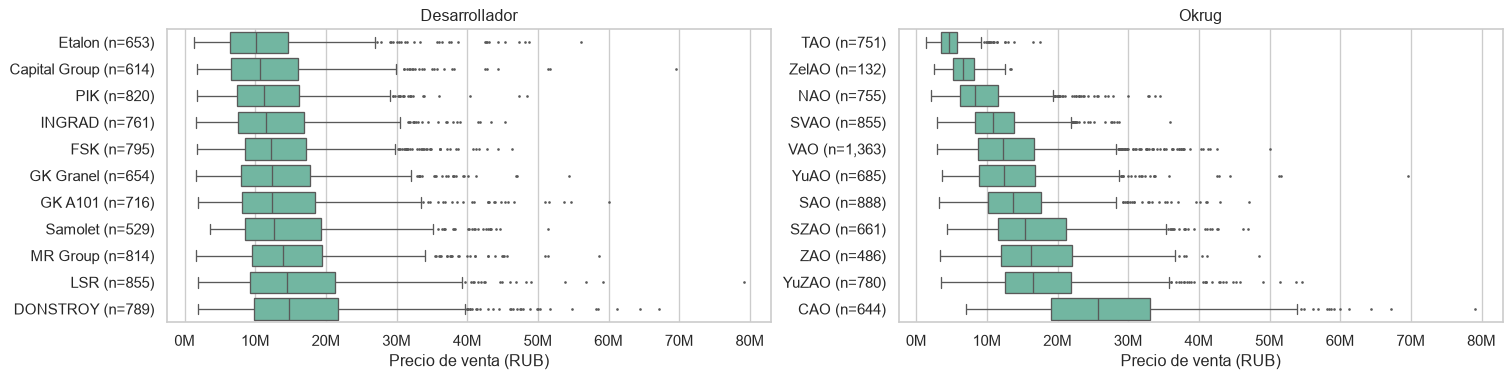

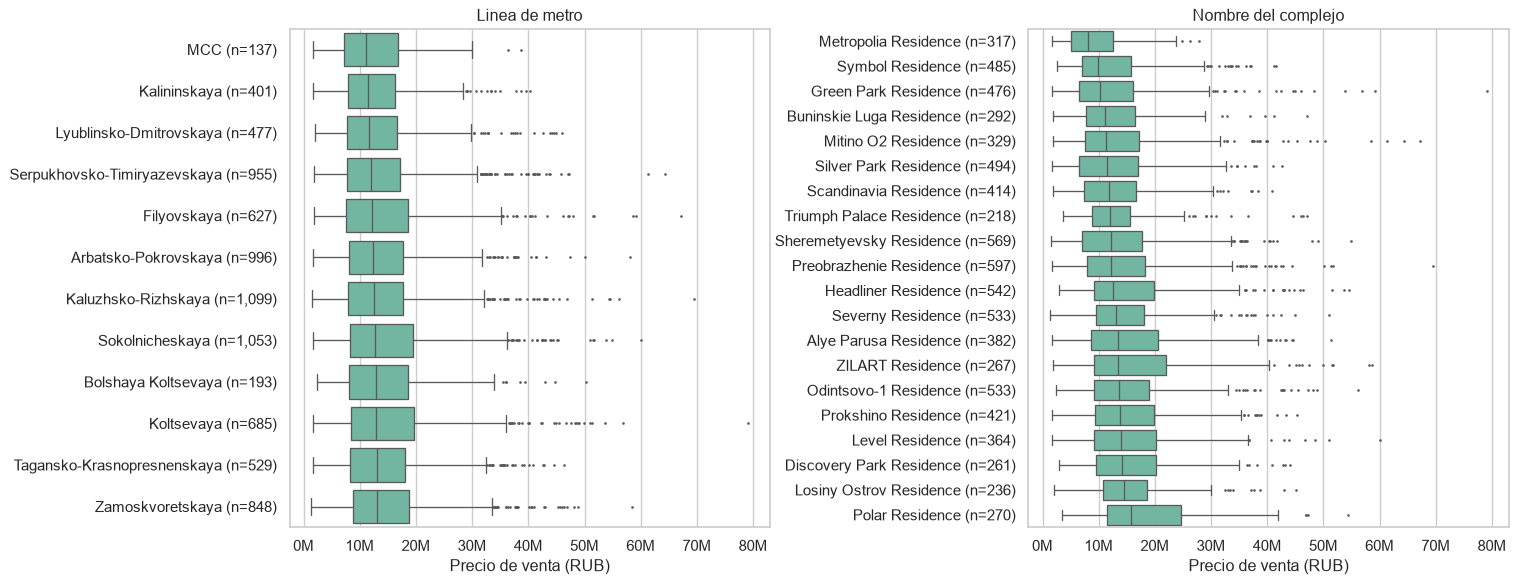

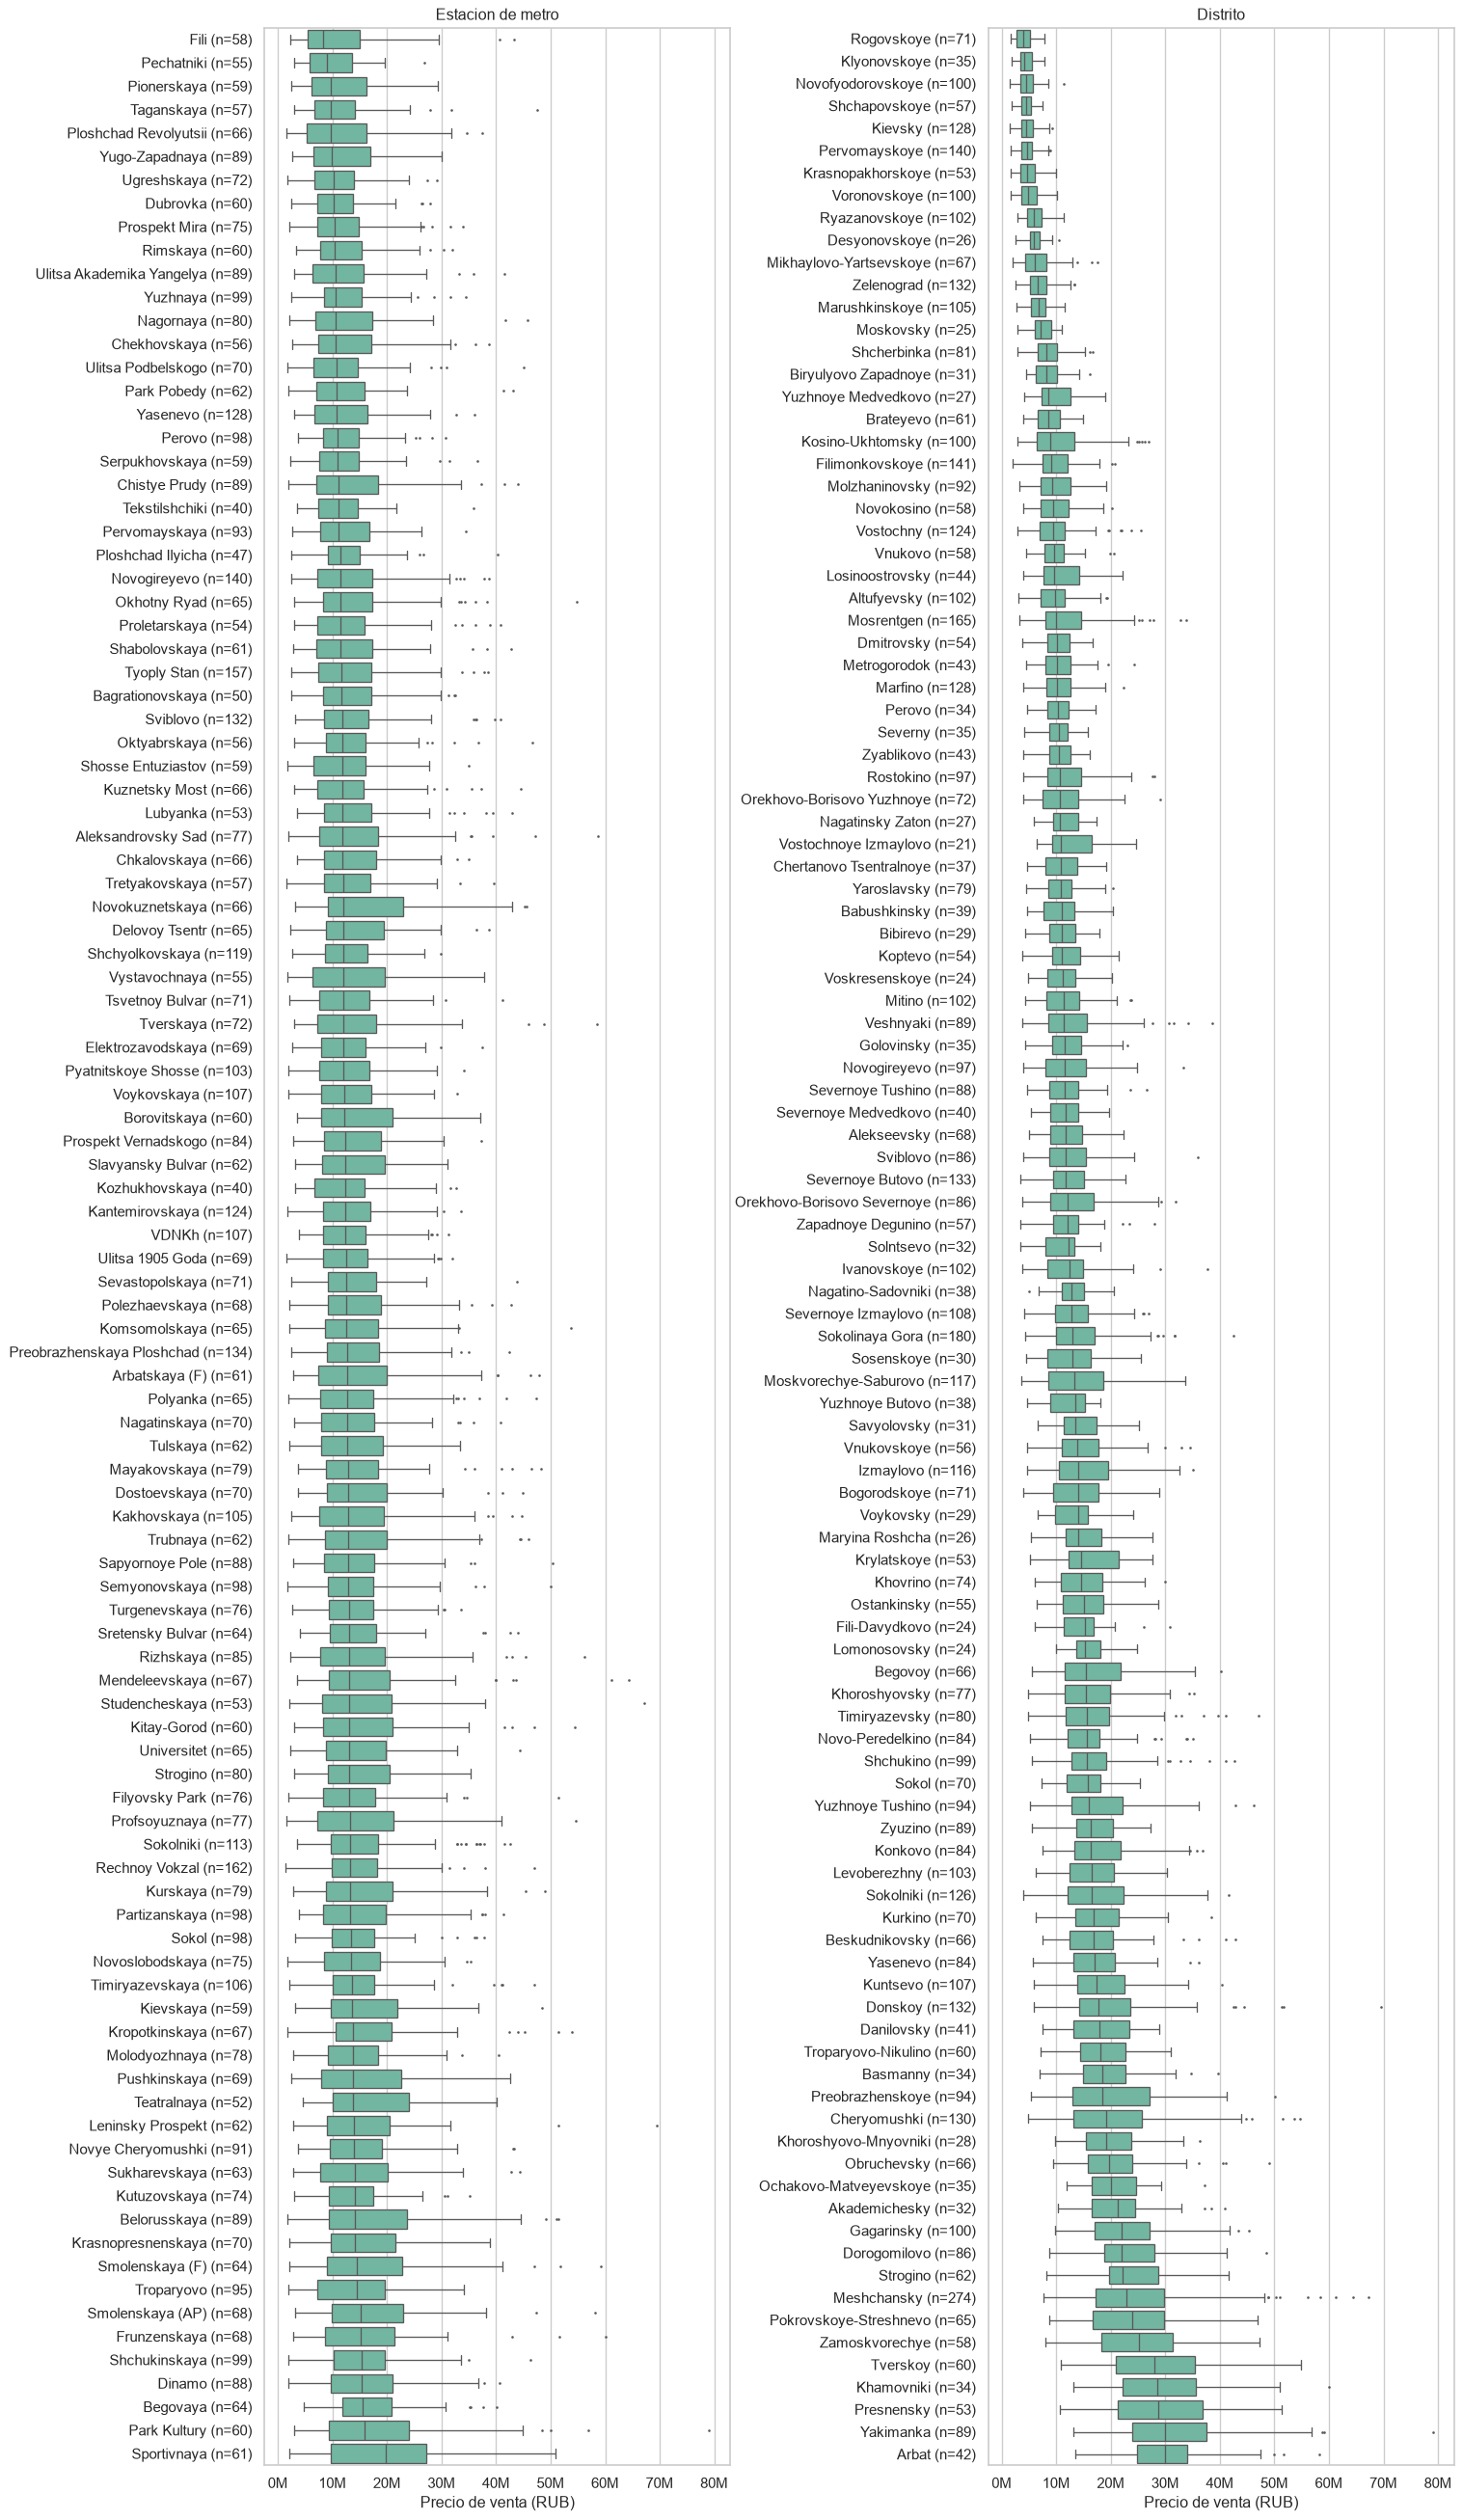

In [9]:
resumen_grupos = {
    variable: datos_bivariados.groupby(variable, observed=True)[objetivo].agg(['count', 'median', 'mean'])
    for variable in categoricas + binarias
}
resumen_categorico_precio = pd.concat(resumen_grupos, names=['variable', 'categoria'])
# Las estadísticas por categoría quedan completas en resumen_categorico_precio.
# En pantalla, los n se integran al gráfico para evitar duplicar tablas.
variables_grupos = sorted(resumen_grupos, key=lambda v: len(resumen_grupos[v]))
for inicio in range(0, len(variables_grupos), 2):
    lote = variables_grupos[inicio:inicio + 2]
    altura = max(4, .24 * max(len(resumen_grupos[v]) for v in lote) + 1.5)
    fig, axes = plt.subplots(1, 2, figsize=(16, altura), squeeze=False)
    for ax, variable in zip(axes.flat, lote):
        grupos = resumen_grupos[variable].sort_values('median')
        orden = grupos.index.tolist()
        sns.boxplot(data=datos_bivariados, y=variable, x=objetivo, order=orden,
                    orient='h', ax=ax, fliersize=1)
        ax.set_yticks(range(len(orden)), [f'{v} (n={grupos.loc[v, "count"]:,.0f})' for v in orden])
        ax.set(title=etiqueta(variable), xlabel='Precio de venta (RUB)', ylabel='')
        formatear_eje_numerico(ax, objetivo)
    for ax in list(axes.flat)[len(lote):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


La mediana del precio aumenta de 10,0 millones RUB en `economy` a 22,4 millones en `premium`: la clase del complejo es candidata a codificación categórica, sin atribuirle un efecto ajustado.

**Variables temporales.** El mes de publicación resume la evolución de la muestra; los años de entrega e inauguración comparan cohortes, sin seguir una misma propiedad en el tiempo. Se informa el tamaño de cada grupo junto con media y mediana.


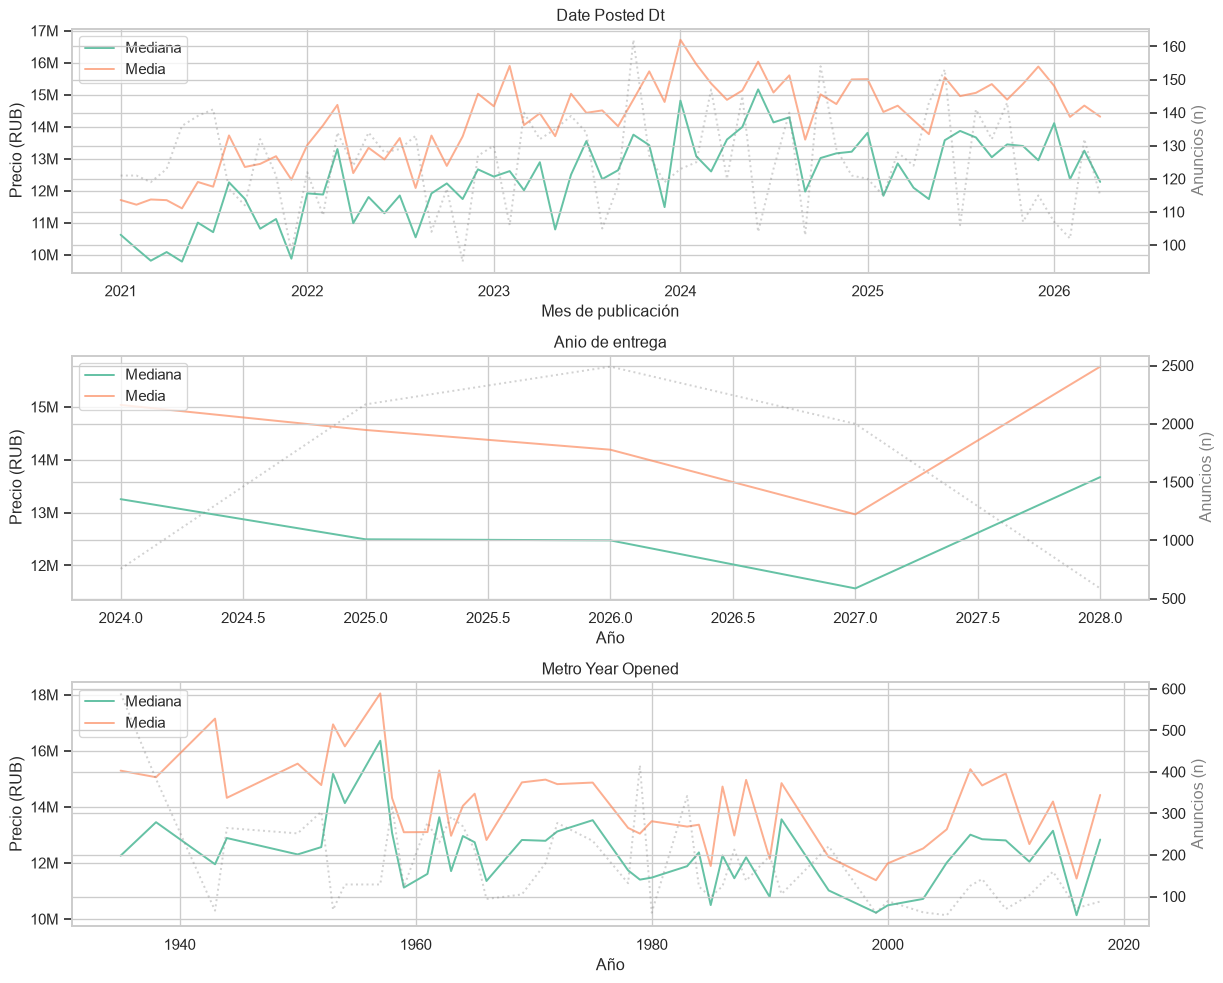

In [10]:
evoluciones_temporales = {}
fig, axes = plt.subplots(len(temporales), 1, figsize=(13, 3.5 * len(temporales)), squeeze=False)
for ax, variable in zip(axes.flat, temporales):
    clave = datos_bivariados[variable].dt.to_period('M') if variable == 'date_posted_dt' else datos_bivariados[variable]
    evolucion = datos_bivariados.groupby(clave, observed=True)[objetivo].agg(['count', 'median', 'mean']).sort_index()
    evoluciones_temporales[variable] = evolucion
    x = evolucion.index.to_timestamp() if variable == 'date_posted_dt' else evolucion.index
    ax.plot(x, evolucion['median'], label='Mediana')
    ax.plot(x, evolucion['mean'], label='Media', alpha=.7)
    ax.set(title=etiqueta(variable), xlabel='Mes de publicación' if variable == 'date_posted_dt' else 'Año', ylabel='Precio (RUB)')
    formatear_eje_numerico(ax, objetivo, axis='y')
    ax.legend(loc='upper left')
    frecuencia = ax.twinx()
    frecuencia.plot(x, evolucion['count'], color='gray', alpha=.35, linestyle=':', label='n')
    frecuencia.set_ylabel('Anuncios (n)', color='gray')
fig.tight_layout()
plt.show()


## 3. Matriz de correlación

Pearson sobre pares disponibles, incluyendo binarias 0/1 y años; se excluyen IDs y `price_per_sqm`.
Se destacan pares de predictores con |r| ≥ 0,80 para evaluar redundancia y VIF posteriormente.
Un r bajo no descarta relaciones no lineales; un r alto no demuestra causalidad. Los indicadores por distrito/mes repiten contexto entre anuncios.


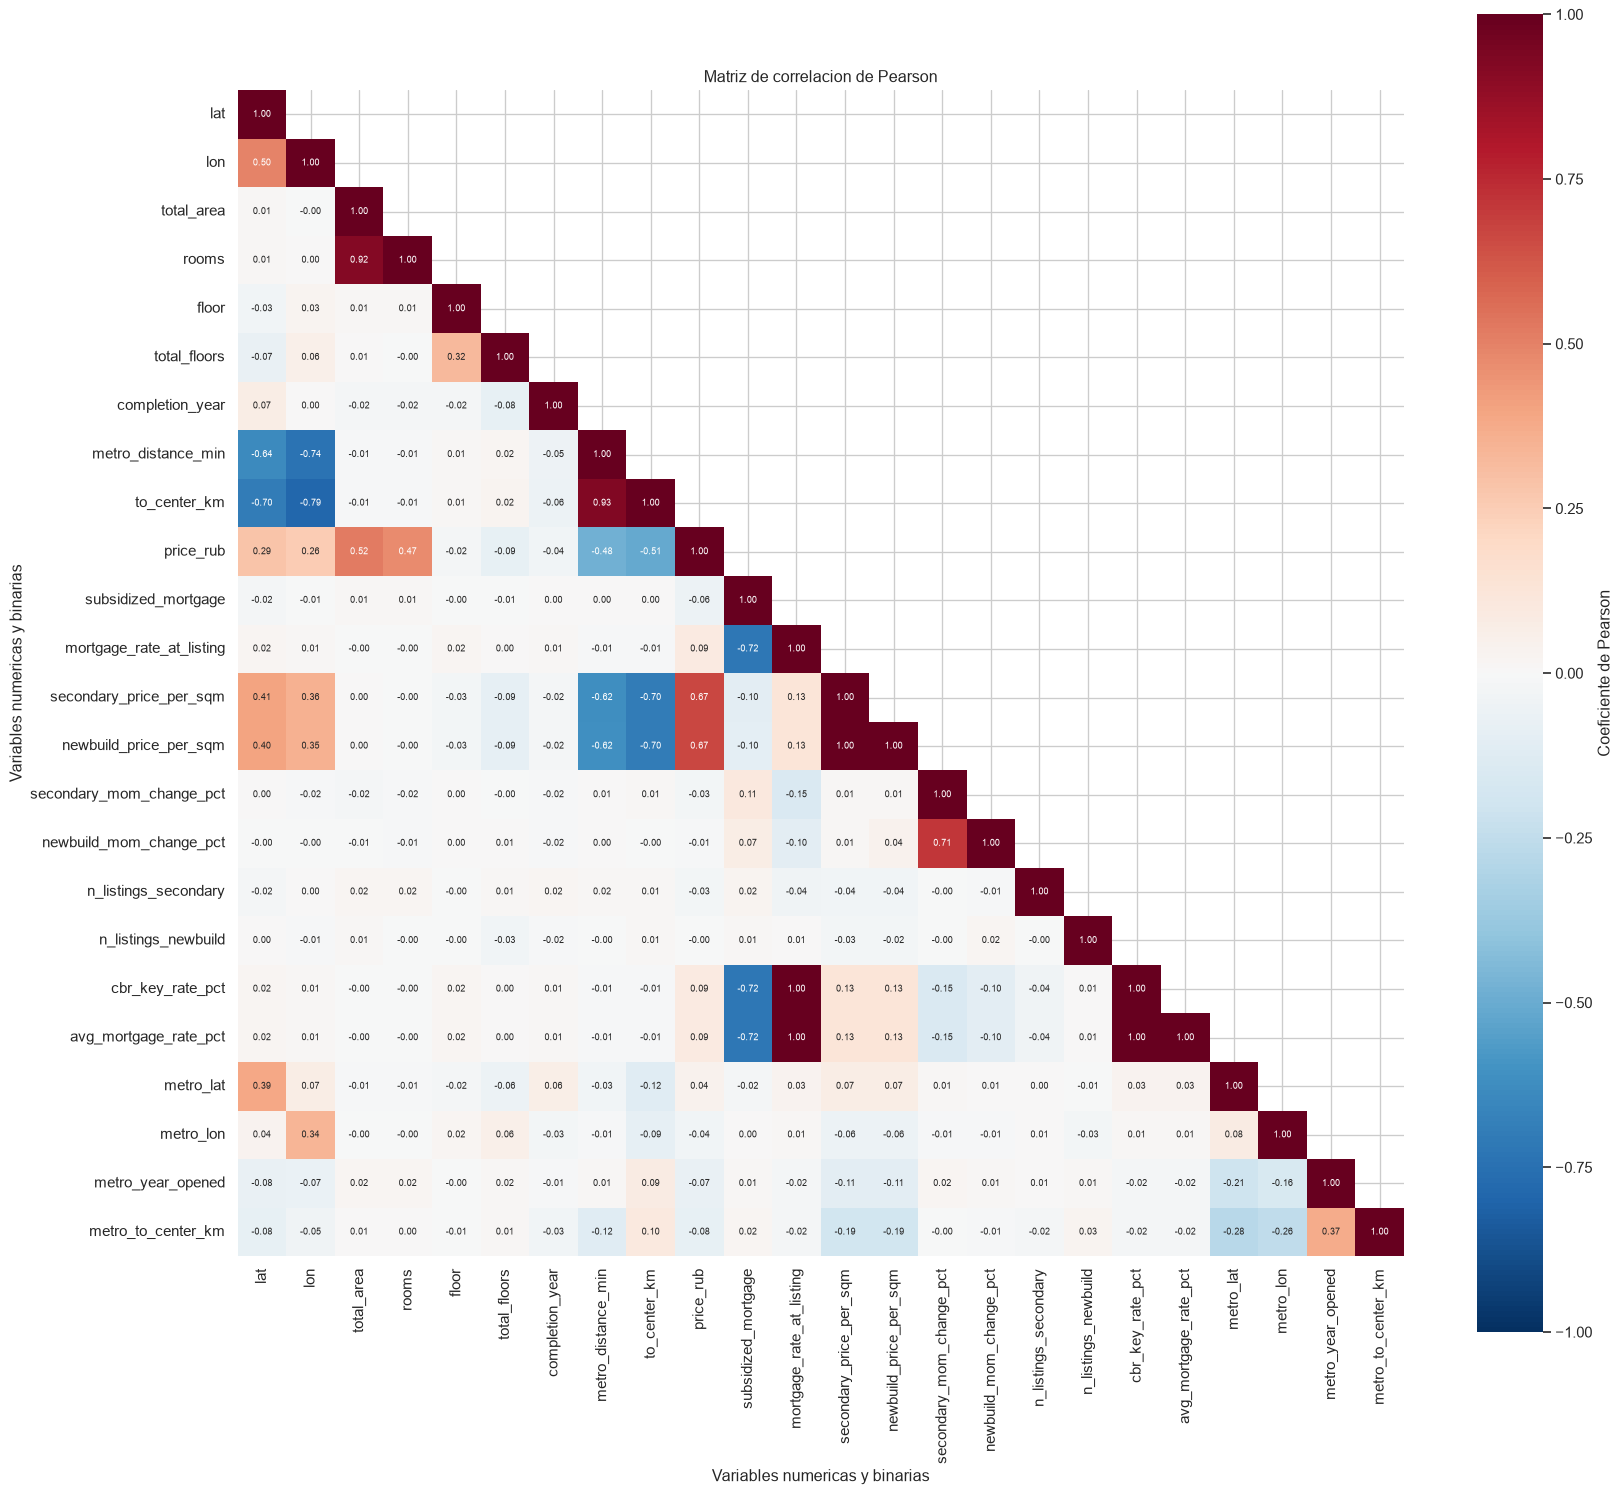

,variable_1,variable_2,Pearson_r,n_pares,ambas_del_join
3,mortgage_rate_at_listing,avg_mortgage_rate_pct,1.00,8000,False
2,mortgage_rate_at_listing,cbr_key_rate_pct,1.00,8000,False
5,cbr_key_rate_pct,avg_mortgage_rate_pct,1.00,8000,True
4,secondary_price_per_sqm,newbuild_price_per_sqm,1.00,8000,True
1,metro_distance_min,to_center_km,0.93,8000,False
0,total_area,rooms,0.92,8000,False


Pares disponibles por correlación: 8,000–8,000.


In [11]:
variables_correlacion = [c for c in datos_bivariados.select_dtypes(include=["number", "bool"]) if c not in exclusiones_bivariadas]
matriz_correlacion = datos_bivariados[variables_correlacion].corr(method="pearson")
conteos_pares = datos_bivariados[variables_correlacion].notna().astype(int).T.dot(datos_bivariados[variables_correlacion].notna().astype(int))
fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(matriz_correlacion, mask=np.triu(np.ones_like(matriz_correlacion, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "Coeficiente de Pearson"})
ax.set(title="Matriz de correlacion de Pearson", xlabel="Variables numericas y binarias", ylabel="Variables numericas y binarias")
fig.tight_layout()
plt.show()
columnas_join = set(district_sales_columns + metro_added_columns)
pares_altos = []
for i, a in enumerate(variables_correlacion):
    for b in variables_correlacion[i + 1:]:
        r = matriz_correlacion.loc[a, b]
        if objetivo not in (a, b) and pd.notna(r) and abs(r) >= .80:
            pares_altos.append({"variable_1": a, "variable_2": b, "Pearson_r": r, "n_pares": conteos_pares.loc[a, b], "ambas_del_join": a in columnas_join and b in columnas_join})
pares_correlacion_alta = pd.DataFrame(pares_altos, columns=["variable_1", "variable_2", "Pearson_r", "n_pares", "ambas_del_join"])
if not pares_correlacion_alta.empty:
    pares_correlacion_alta = pares_correlacion_alta.loc[pares_correlacion_alta.Pearson_r.abs().sort_values(ascending=False).index]

# La matriz y los n completos quedan en matriz_correlacion y conteos_pares.
display(pares_correlacion_alta)
print(f'Pares disponibles por correlación: {conteos_pares.to_numpy().min():,}–{conteos_pares.to_numpy().max():,}.')


La tabla identifica también los pares procedentes de ambos auxiliares (`ambas_del_join`). Los coeficientes con el precio y sus n se consultan en `resultados_regresiones`, sin repetir la matriz en formato tabular.


In [12]:
carpeta_exportacion = PROJECT_ROOT / "Ventas" / "Propiedades_Nuevas" / "data"
carpeta_exportacion.mkdir(parents=True, exist_ok=True)
ruta_csv_integrado = carpeta_exportacion / "newbuilds_integrado.csv"
df_exportacion.to_csv(ruta_csv_integrado, index=False, encoding="utf-8")

# El parseo explícito de fechas también sirve de ejemplo para los siguientes notebooks.
df_integrado_recargado = pd.read_csv(
    ruta_csv_integrado, encoding="utf-8", parse_dates=["date_posted_dt"], float_precision="round_trip",
)
assert df_integrado_recargado.shape == df_exportacion.shape
assert df_integrado_recargado.columns.tolist() == df_exportacion.columns.tolist()
assert df_integrado_recargado["id"].is_unique
assert df_integrado_recargado["id"].nunique() == df_exportacion["id"].nunique() == 8000
assert df_integrado_recargado["complex_id"].nunique() == df_exportacion["complex_id"].nunique()
pd.testing.assert_series_equal(df_integrado_recargado.isna().sum(), df_exportacion.isna().sum())

# Igualdad exacta de todos los valores y su orden; CSV no preserva dtype category.
df_comprobacion_csv = df_integrado_recargado.copy()
for columna in df_exportacion.select_dtypes(include="category").columns:
    df_comprobacion_csv[columna] = df_comprobacion_csv[columna].astype(df_exportacion[columna].dtype)
pd.testing.assert_frame_equal(df_comprobacion_csv, df_exportacion, check_dtype=False, check_exact=True)
assert pd.api.types.is_datetime64_any_dtype(df_integrado_recargado["date_posted_dt"])
assert df_integrado_recargado["date_posted_dt"].notna().all()
pd.testing.assert_series_equal(
    pd.to_datetime(df_integrado_recargado["date_posted"], format="%Y-%m-%d", errors="raise"),
    df_integrado_recargado["date_posted_dt"], check_names=False,
)
assert df_integrado_recargado["year_month"].eq(df_integrado_recargado["date_posted_dt"].dt.strftime("%Y-%m")).all()

resumen_exportacion = pd.DataFrame([{
    "archivo": str(ruta_csv_integrado.relative_to(PROJECT_ROOT)),
    "filas": len(df_integrado_recargado), "columnas": df_integrado_recargado.shape[1],
    "id_unicos": df_integrado_recargado["id"].nunique(),
    "complejos_unicos": df_integrado_recargado["complex_id"].nunique(),
    "id_duplicados": int(df_integrado_recargado["id"].duplicated().sum()),
    "celdas_nulas": int(df_integrado_recargado.isna().sum().sum()),
    "fecha_desde": df_integrado_recargado["date_posted_dt"].min(),
    "fecha_hasta": df_integrado_recargado["date_posted_dt"].max(),
    "columnas_y_valores_verificados": True,
}])

print(f'CSV integrado verificado: {ruta_csv_integrado.relative_to(PROJECT_ROOT)} '
      f'({len(df_integrado_recargado):,} filas × {df_integrado_recargado.shape[1]} columnas).')


CSV integrado verificado: Ventas\Propiedades_Nuevas\data\newbuilds_integrado.csv (8,000 filas × 41 columnas).


## Hallazgos para el modelado

Los precios distritales (r ≈ 0,67), superficie (0,52) y habitaciones (0,47) son candidatos; verificar disponibilidad y fuga de las referencias mensuales.  
Distancias al centro (−0,51) y al metro (−0,48) aportan señal; la mediana por clase crece de 10,0 M RUB (economy) a 22,4 M (premium).  
Tasas (r ≈ 1), precios distritales (≈ 1), superficie/habitaciones (0,92) y distancias (0,93) requieren evaluar redundancia y VIF.  
La asimetría positiva del precio y sus extremos justifican evaluar logaritmos, influencia y heterocedasticidad, sin eliminaciones automáticas.  
Pearson débil no basta para descartar predictores; validar OLS considerando categorías, cohortes y contexto compartido por complejo y distrito/mes.
